# AirSense: Air Quality Category Prediction

We use Rohan Rao's real **city_day.csv** from [Air Quality Data in India](https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india).


## 1. Import libraries and define the six input features

In [3]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, io, json, subprocess, sys, tempfile, urllib.request, zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

ROOT = Path.cwd()  # Start Jupyter from the airsense folder.
DATA_PATH = ROOT / "city_day.csv"
FEATURES = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"]
CATEGORIES = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
SOURCE = "https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india"
sns.set_theme(style="whitegrid", palette="Set2")
print("Project folder:", ROOT)

Project folder: c:\Users\indra\Documents\ML\airsense


## 2. Load the dataset



In [4]:
if not DATA_PATH.exists():
    with tempfile.TemporaryDirectory() as folder:
        staging = Path(folder)
        cli = Path(sys.executable).parent / ("kaggle.exe" if sys.platform == "win32" else "kaggle")
        try:
            completed = subprocess.run([str(cli), "datasets", "download", "-d",
                "rohanrao/air-quality-data-in-india", "-f", "city_day.csv", "-p", folder],
                capture_output=True, timeout=120)
            for file in staging.iterdir():
                if zipfile.is_zipfile(file):
                    with zipfile.ZipFile(file) as archive:
                        for name in archive.namelist():
                            if Path(name).name == "city_day.csv":
                                DATA_PATH.write_bytes(archive.read(name))
                elif file.name == "city_day.csv":
                    DATA_PATH.write_bytes(file.read_bytes())
        except (OSError, subprocess.TimeoutExpired):
            print("Kaggle CLI could not complete the download.")
        if not DATA_PATH.exists():
            try:
                url = "https://www.kaggle.com/api/v1/datasets/download/rohanrao/air-quality-data-in-india"
                with urllib.request.urlopen(url, timeout=120) as response:
                    with zipfile.ZipFile(io.BytesIO(response.read())) as archive:
                        DATA_PATH.write_bytes(archive.read("city_day.csv"))
            except Exception as error:
                print("Kaggle download unavailable:", type(error).__name__)
if not DATA_PATH.exists():
    raise FileNotFoundError("Download city_day.csv from " + SOURCE + " and place it beside this notebook, then Run All.")
print("Dataset file found:", DATA_PATH.name, "— validating next.")

Dataset file found: city_day.csv — validating next.


## 3. validate and inspect the data

In [5]:
raw = pd.read_csv(DATA_PATH)
required = ["City", "Date", "AQI", "AQI_Bucket", *FEATURES]
missing_columns = set(required) - set(raw.columns)
if missing_columns or raw.empty:
    raise ValueError(f"Invalid dataset: missing columns {missing_columns}, rows={len(raw)}")
print("Raw shape:", raw.shape)
display(raw.head())
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing_percent": raw.isna().mean().mul(100).round(2)}))

Raw shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


,dtype,missing_percent
City,object,0.00
Date,object,0.00
PM2.5,float64,15.57
PM10,float64,37.72
NO,float64,12.13
NO2,float64,12.14
NOx,float64,14.17
NH3,float64,34.97
CO,float64,6.97
SO2,float64,13.05


## 4. Clean the data


In [6]:
df = raw.drop_duplicates().copy()
duplicates_removed = len(raw) - len(df)
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d", errors="coerce")
if df.Date.isna().any() or df.City.isna().any():
    raise ValueError("Invalid dates or missing city names: inspect the source file.")
df["AQI_Bucket"] = df.AQI_Bucket.astype("string").str.strip()
missing_labels = int(df.AQI_Bucket.isna().sum())
df = df.dropna(subset=["AQI_Bucket"])
unknown = set(df.AQI_Bucket) - set(CATEGORIES)
if unknown or df.empty:
    raise ValueError(f"Invalid or absent labels: {unknown}")
negative_counts = {}
for column in [*FEATURES, "AQI"]:
    df[column] = pd.to_numeric(df[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
    negative_counts[column] = int((df[column] < 0).sum())
    df.loc[df[column] < 0, column] = np.nan
df = df.sort_values(["Date", "City"]).reset_index(drop=True)
print(f"Removed {duplicates_removed} exact duplicates and {missing_labels} unlabeled observations.")
print("Negative values replaced:", negative_counts)
print("Labeled observations:", len(df), "Cities:", df.City.nunique())
print("Dates:", df.Date.min().date(), "to", df.Date.max().date())
display(df[FEATURES].isna().mean().mul(100).rename("Missing (%)").to_frame())
display(df.AQI_Bucket.value_counts().reindex(CATEGORIES, fill_value=0).rename("Observations").to_frame())

Removed 0 exact duplicates and 4681 unlabeled observations.
Negative values replaced: {'PM2.5': 0, 'PM10': 0, 'NO2': 0, 'SO2': 0, 'CO': 0, 'O3': 0, 'AQI': 0}
Labeled observations: 24850 Cities: 26
Dates: 2015-01-01 to 2020-07-01


,Missing (%)
PM2.5,2.728370
PM10,28.515091
NO2,1.573441
SO2,2.434608
CO,1.790744
O3,3.247485


,Observations
AQI_Bucket,
Good,1341
Satisfactory,8224
Moderate,8829
Poor,2781
Very Poor,2337
Severe,1338


## 5. Explore the historical data

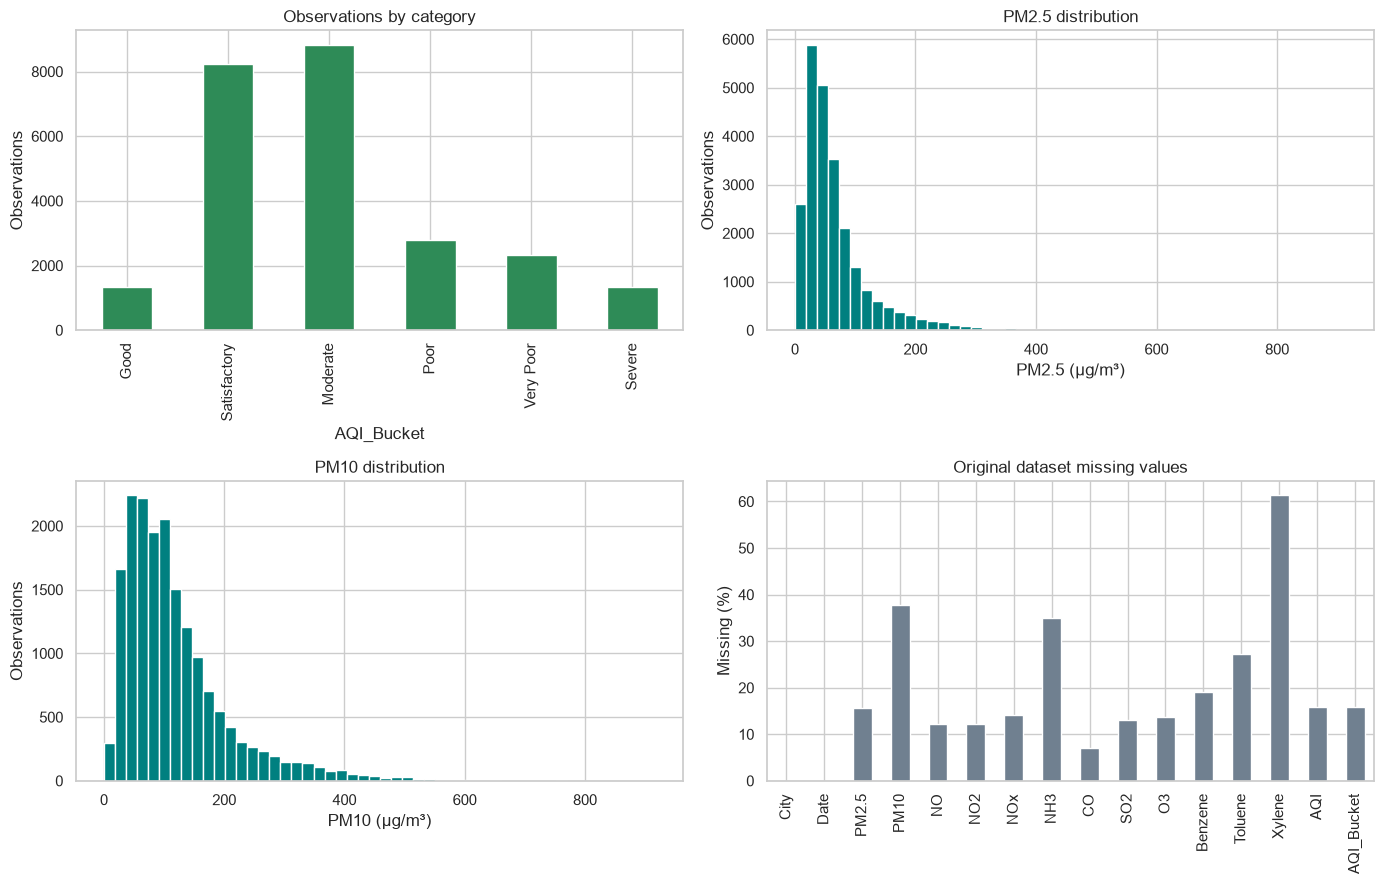

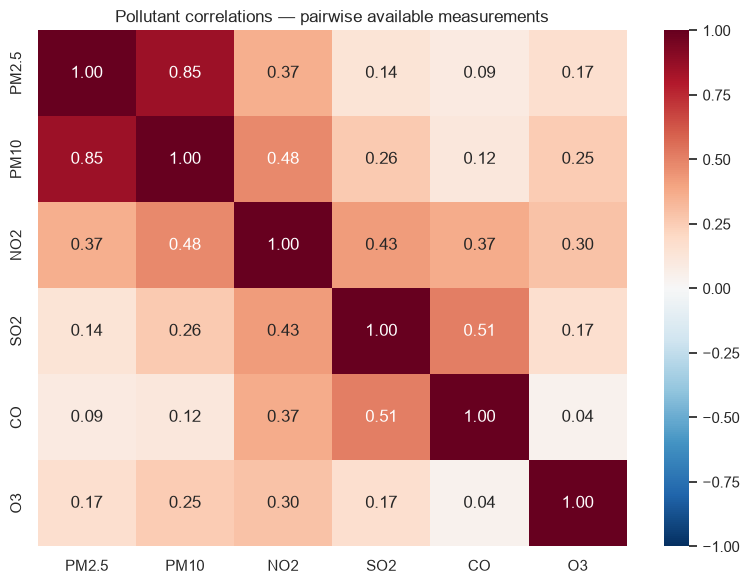

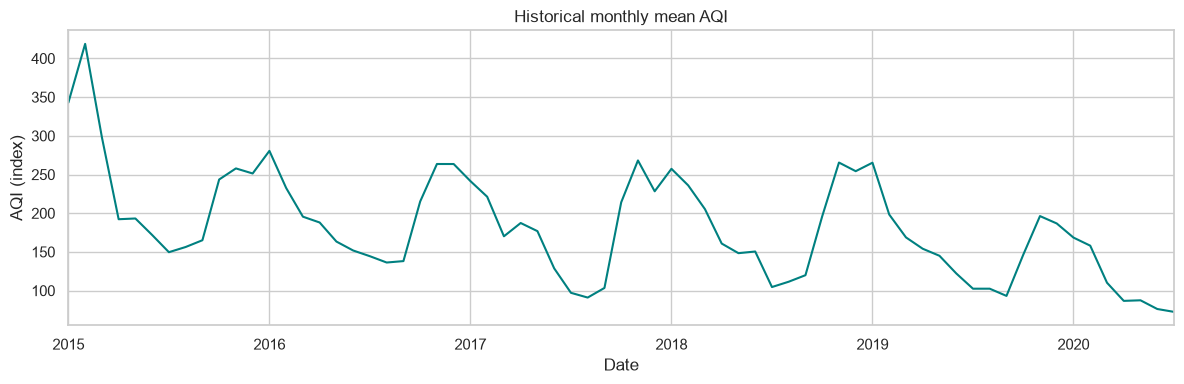

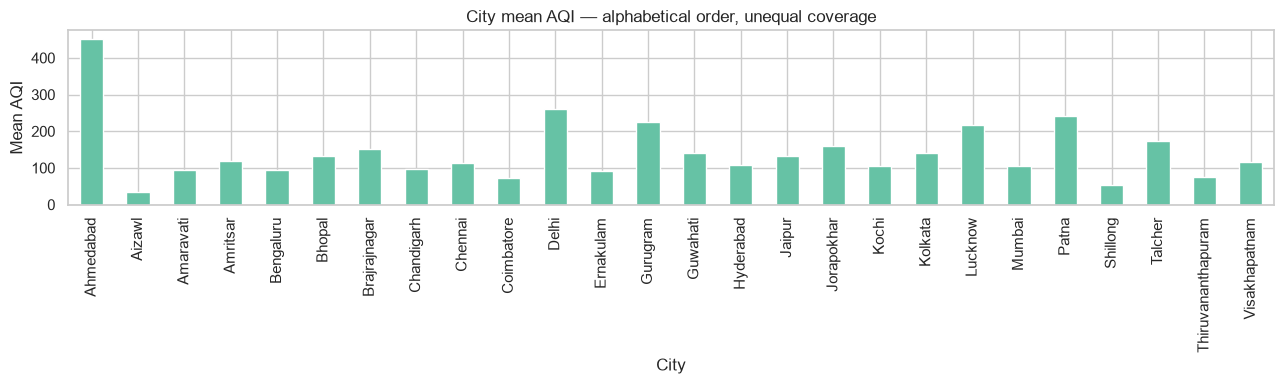

,mean_AQI,observations
City,,
Ahmedabad,452.122939,1334
Aizawl,34.765766,111
Amaravati,95.299643,841
Amritsar,119.920959,1126
Bengaluru,94.318325,1910
Bhopal,132.827338,278
Brajrajnagar,150.280505,713
Chandigarh,96.498328,299
Chennai,114.502654,1884


City averages differ in reporting counts, dates and seasons; they are not a fair city ranking.


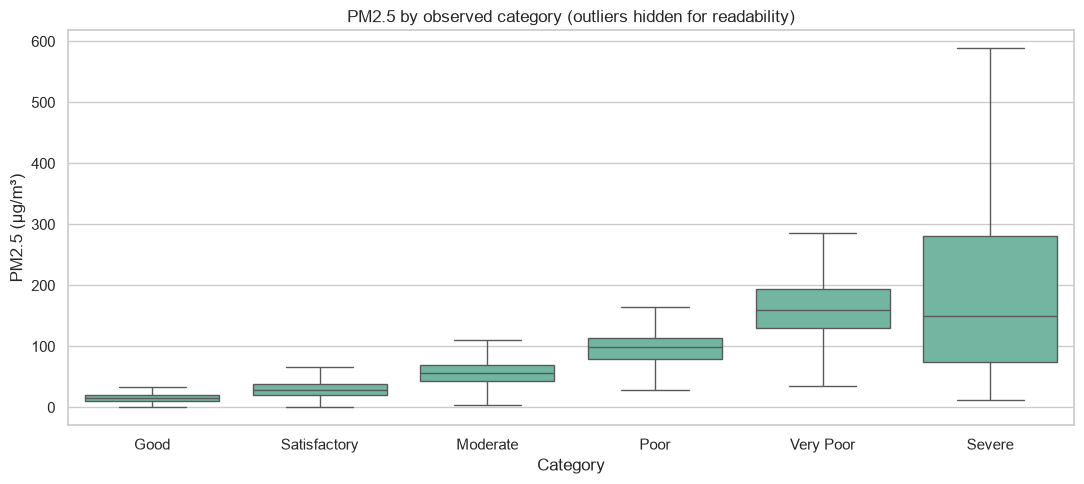

Pooled monthly trends may reflect changes in which cities report data.


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
df.AQI_Bucket.value_counts().reindex(CATEGORIES, fill_value=0).plot.bar(ax=axes[0, 0], color="seagreen", title="Observations by category")
axes[0, 0].set_ylabel("Observations")
for ax, feature in zip([axes[0, 1], axes[1, 0]], ["PM2.5", "PM10"]):
    ax.hist(df[feature].dropna(), bins=50, color="teal")
    ax.set(title=f"{feature} distribution", xlabel=f"{feature} (µg/m³)", ylabel="Observations")
raw.isna().mean().mul(100).plot.bar(ax=axes[1, 1], title="Original dataset missing values", color="slategrey")
axes[1, 1].set_ylabel("Missing (%)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r")
plt.title("Pollutant correlations — pairwise available measurements")
plt.tight_layout(); plt.show()

monthly = df.set_index("Date").AQI.resample("MS").mean()
monthly.plot(figsize=(12, 4), title="Historical monthly mean AQI", color="teal")
plt.ylabel("AQI (index)"); plt.tight_layout(); plt.show()

city_summary = df.groupby("City").AQI.agg(mean_AQI="mean", observations="count")
city_summary.mean_AQI.plot.bar(figsize=(13, 4), title="City mean AQI — alphabetical order, unequal coverage")
plt.ylabel("Mean AQI"); plt.tight_layout(); plt.show()
display(city_summary)
print("City averages differ in reporting counts, dates and seasons; they are not a fair city ranking.")

plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x="AQI_Bucket", y="PM2.5", order=CATEGORIES, showfliers=False)
plt.title("PM2.5 by observed category (outliers hidden for readability)")
plt.xlabel("Category"); plt.ylabel("PM2.5 (µg/m³)"); plt.tight_layout(); plt.show()
print("Pooled monthly trends may reflect changes in which cities report data.")

## 6. Split chronologically


In [8]:
dates = sorted(df.Date.unique())
if len(dates) < 10:
    raise ValueError("Too few distinct dates to split.")
validation_start, test_start = dates[int(len(dates) * .64)], dates[int(len(dates) * .8)]
train = df[df.Date < validation_start].copy()
validation = df[(df.Date >= validation_start) & (df.Date < test_start)].copy()
test = df[df.Date >= test_start].copy()
assert train.Date.max() < validation.Date.min() <= validation.Date.max() < test.Date.min()
assert set(train.AQI_Bucket) == set(CATEGORIES), "Training must contain all six categories."
assert not train[FEATURES].isna().all().any(), "A training feature is entirely missing."
assert not set(FEATURES) & {"AQI", "AQI_Bucket", "City", "Date"}
split_details = {}
for name, part in [("Training", train), ("Validation", validation), ("Test", test)]:
    split_details[name] = {"start": str(part.Date.min().date()), "end": str(part.Date.max().date()), "rows": len(part)}
    print(name, split_details[name], "Absent classes:", sorted(set(CATEGORIES) - set(part.AQI_Bucket)))
display(pd.DataFrame(split_details).T)

Training {'start': '2015-01-01', 'end': '2018-07-08', 'rows': 10454} Absent classes: []
Validation {'start': '2018-07-09', 'end': '2019-05-26', 'rows': 5564} Absent classes: []
Test {'start': '2019-05-27', 'end': '2020-07-01', 'rows': 8832} Absent classes: []


,start,end,rows
Training,2015-01-01,2018-07-08,10454
Validation,2018-07-09,2019-05-26,5564
Test,2019-05-27,2020-07-01,8832


## 7. Train a baseline, Decision Tree and Random Forest

In [9]:
def metric_scores(actual, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(actual, predicted, labels=CATEGORIES, average="macro", zero_division=0)
    weighted = precision_recall_fscore_support(actual, predicted, labels=CATEGORIES, average="weighted", zero_division=0)[2]
    return {"accuracy": float(accuracy_score(actual, predicted)), "macro_precision": float(precision),
            "macro_recall": float(recall), "macro_f1": float(f1), "weighted_f1": float(weighted)}

candidates = [("Dummy", DummyClassifier(strategy="most_frequent"))]
for depth, leaf in [(6, 8), (10, 5), (16, 3)]:
    candidates.append(("Decision Tree", DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
        min_samples_split=10, class_weight="balanced", random_state=42)))
for depth, leaf in [(12, 2), (20, 2), (None, 1)]:
    candidates.append(("Random Forest", RandomForestClassifier(n_estimators=160, max_depth=depth,
        min_samples_leaf=leaf, class_weight="balanced_subsample", random_state=42, n_jobs=-1)))

best_by_name, trials = {}, []
for name, classifier in candidates:
    pipeline = Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("classifier", classifier)])
    pipeline.fit(train[FEATURES], train.AQI_Bucket)
    scores = metric_scores(validation.AQI_Bucket, pipeline.predict(validation[FEATURES]))
    trials.append({"model": name, "parameters": str(classifier), **scores})
    if name not in best_by_name or scores["macro_f1"] > best_by_name[name]["scores"]["macro_f1"]:
        best_by_name[name] = {"pipeline": pipeline, "scores": scores}
comparison = [{"model": name, **item["scores"]} for name, item in best_by_name.items()]
display(pd.DataFrame(trials))
display(pd.DataFrame(comparison))
selected_name = max(["Decision Tree", "Random Forest"], key=lambda name: best_by_name[name]["scores"]["macro_f1"])
print("Selected using validation macro F1:", selected_name)
if best_by_name[selected_name]["scores"]["macro_f1"] <= best_by_name["Dummy"]["scores"]["macro_f1"]:
    print("Warning: selected classifier did not outperform the baseline. Investigate before use.")

,model,parameters,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Dummy,DummyClassifier(strategy='most_frequent'),0.382818,0.063803,0.166667,0.092280,0.211958
1,Decision Tree,DecisionTreeClassifier(class_weight='balanced'...,0.619339,0.613796,0.693374,0.605226,0.638492
2,Decision Tree,DecisionTreeClassifier(class_weight='balanced'...,0.707045,0.644853,0.694793,0.654160,0.717244
3,Decision Tree,DecisionTreeClassifier(class_weight='balanced'...,0.687455,0.619967,0.668412,0.634651,0.694590
4,Random Forest,RandomForestClassifier(class_weight='balanced_...,0.775521,0.741391,0.714226,0.724339,0.774975
5,Random Forest,RandomForestClassifier(class_weight='balanced_...,0.772825,0.737861,0.692972,0.710788,0.770716
6,Random Forest,RandomForestClassifier(class_weight='balanced_...,0.765636,0.734487,0.657123,0.680872,0.760103


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Dummy,0.382818,0.063803,0.166667,0.092280,0.211958
1,Decision Tree,0.707045,0.644853,0.694793,0.654160,0.717244
2,Random Forest,0.775521,0.741391,0.714226,0.724339,0.774975


Selected using validation macro F1: Random Forest


## 8. Refit the selected model and evaluate once on the untouched test period

,Test score
accuracy,0.777514
macro_precision,0.755794
macro_recall,0.763036
macro_f1,0.757493
weighted_f1,0.777247


,precision,recall,f1-score,support
Good,0.650320,0.660888,0.655562,923.000000
Satisfactory,0.787491,0.855819,0.820234,3884.000000
Moderate,0.850644,0.714234,0.776494,2775.000000
Poor,0.636608,0.734472,0.682048,644.000000
Very Poor,0.766484,0.736148,0.751009,379.000000
Severe,0.843220,0.876652,0.859611,227.000000
accuracy,0.777514,0.777514,0.777514,0.777514
macro avg,0.755794,0.763036,0.757493,8832.000000
weighted avg,0.782527,0.777514,0.777247,8832.000000


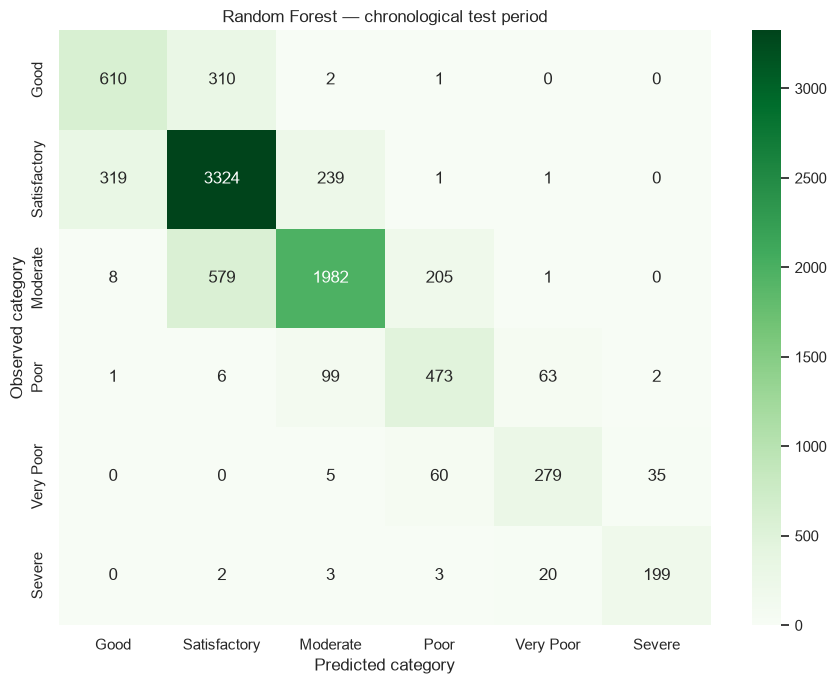

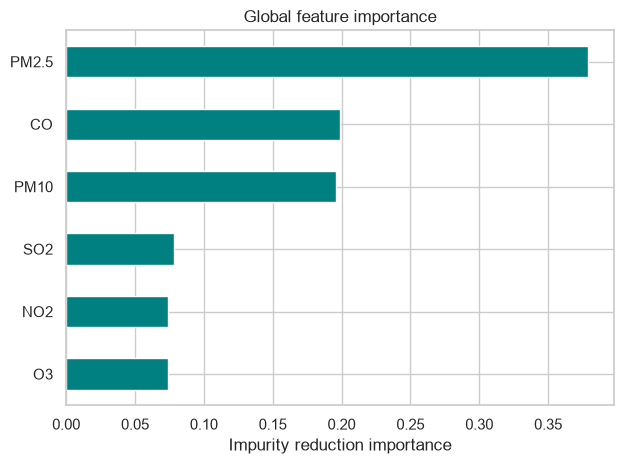

Importance is not causal; correlated pollutants can share importance.


In [10]:
development = pd.concat([train, validation])
best_model = clone(best_by_name[selected_name]["pipeline"])
best_model.fit(development[FEATURES], development.AQI_Bucket)
predicted = best_model.predict(test[FEATURES])
test_metrics = metric_scores(test.AQI_Bucket, predicted)
report = classification_report(test.AQI_Bucket, predicted, labels=CATEGORIES, output_dict=True, zero_division=0)
matrix = confusion_matrix(test.AQI_Bucket, predicted, labels=CATEGORIES)
display(pd.Series(test_metrics, name="Test score").to_frame())
display(pd.DataFrame(report).T)
plt.figure(figsize=(9, 7))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Greens", xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.xlabel("Predicted category"); plt.ylabel("Observed category")
plt.title(f"{selected_name} — chronological test period"); plt.tight_layout(); plt.show()
importance = pd.Series(best_model.named_steps["classifier"].feature_importances_, index=FEATURES)
importance.sort_values().plot.barh(title="Global feature importance", color="teal")
plt.xlabel("Impurity reduction importance"); plt.tight_layout(); plt.show()
print("Importance is not causal; correlated pollutants can share importance.")

## 9. Save the pipeline, results and cleaned data for Streamlit

In [ ]:
model_path = ROOT / "airsense_model.joblib"
joblib.dump(best_model, model_path)

df.to_csv(ROOT / "cleaned_data.csv", index=False)
print("Saved airsense_model.joblib, model_info.json and cleaned_data.csv")

Saved airsense_model.joblib, model_info.json and cleaned_data.csv


## 10. Verify saved-model predictions

In [12]:
loaded_model = joblib.load(model_path)
example = pd.DataFrame([{f: info["training_ranges"][f]["median"] for f in FEATURES}], columns=FEATURES)
result = loaded_model.predict(example)[0]
probabilities = loaded_model.predict_proba(example)[0]
assert result in CATEGORIES
assert probabilities.shape == (6,) and np.isclose(probabilities.sum(), 1)
assert list(loaded_model.feature_names_in_) == FEATURES
np.testing.assert_allclose(loaded_model.named_steps["imputer"].statistics_, development[FEATURES].median().to_numpy())
missing_example = example.copy()
missing_example.loc[0, "PM10"] = np.nan
assert loaded_model.predict(missing_example)[0] in CATEGORIES
np.testing.assert_array_equal(loaded_model.predict(test[FEATURES].head()), best_model.predict(test[FEATURES].head()))
display(example)
print("Predicted category:", result)
print("Model-estimated probabilities (uncalibrated):", dict(zip(loaded_model.classes_, probabilities)))
print("All saved-model checks passed. Start the frontend: streamlit run app.py")

,PM2.5,PM10,NO2,SO2,CO,O3
0,57.665,111.56,25.39,8.87,1.01,32.04


Predicted category: Good
Model-estimated probabilities (uncalibrated): {'Good': np.float64(0.4551278539915019), 'Moderate': np.float64(0.1715286497252221), 'Poor': np.float64(0.05163377176814714), 'Satisfactory': np.float64(0.2610900698642751), 'Severe': np.float64(0.03791213275130797), 'Very Poor': np.float64(0.022707521899545474)}
All saved-model checks passed. Start the frontend: streamlit run app.py
